In [1]:
import pandas as pd
import numpy as numpy
import matplotlib.pyplot as plt
import seaborn as sns   

In [2]:
print("Email Spam Detection Project")
print("Libraries imported successfully!")

Email Spam Detection Project
Libraries imported successfully!


In [3]:
df = pd.read_csv("C:/Users/yaman/OneDrive/Desktop/Email Spam Detection/dataset/Enron_Txt_fn.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
df.head()

,label,email,filename
0,0,['Subject: christmas tree farm pictures \n'],0001.1999-12-10.farmer.ham.txt
1,0,['Subject: re : rankings \nthank you .'],0001.1999-12-10.kaminski.ham.txt
2,0,['Subject: leadership development pilot \nsal...,0001.2000-01-17.beck.ham.txt
3,0,"[""Subject: key dates and impact of upcoming sa...",0001.2000-06-06.lokay.ham.txt
4,0,['Subject: key hr issues going forward \na ) ...,0001.2001-02-07.kitchen.ham.txt


In [5]:
print("Dataset Shape:", df.shape)

print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Dataset Shape: (33716, 3)
Total Rows: 33716
Total Columns: 3


In [6]:
print(df.columns)

Index(['label', 'email', 'filename'], dtype='str')


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 33716 entries, 0 to 33715
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   label     33716 non-null  int64
 1   email     33716 non-null  str  
 2   filename  33716 non-null  str  
dtypes: int64(1), str(2)
memory usage: 790.3 KB


In [8]:
print(df.isnull().sum())

label       0
email       0
filename    0
dtype: int64


In [9]:
print("Total Duplicate Records:", df.duplicated().sum())

Total Duplicate Records: 0


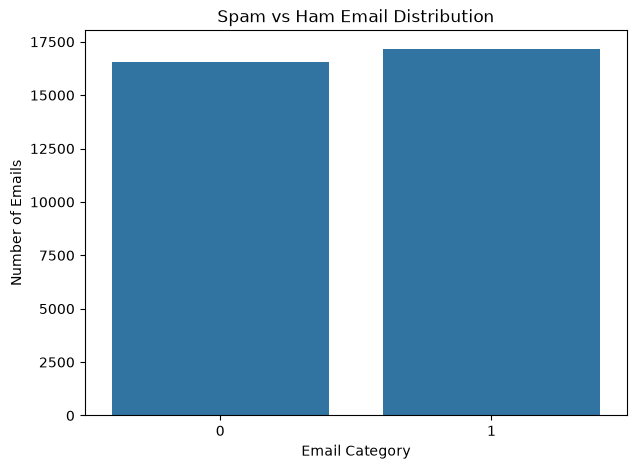

In [10]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='label')

plt.title("Spam vs Ham Email Distribution")
plt.xlabel("Email Category")
plt.ylabel("Number of Emails")

plt.show()

In [11]:
# Count spam and ham emails

print(df['label'].value_counts())

label
1    17171
0    16545
Name: count, dtype: int64


In [12]:
# Calculate percentage distribution

print(df['label'].value_counts(normalize=True) * 100)

label
1    50.928343
0    49.071657
Name: proportion, dtype: float64


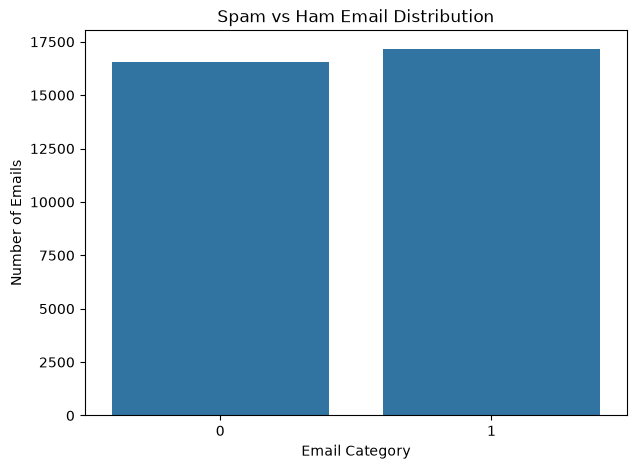

In [13]:


plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='label')

plt.title("Spam vs Ham Email Distribution")
plt.xlabel("Email Category")
plt.ylabel("Number of Emails")

plt.show()

In [14]:
print(df[['label', 'filename']].head(10))

   label                          filename
0      0    0001.1999-12-10.farmer.ham.txt
1      0  0001.1999-12-10.kaminski.ham.txt
2      0      0001.2000-01-17.beck.ham.txt
3      0     0001.2000-06-06.lokay.ham.txt
4      0   0001.2001-02-07.kitchen.ham.txt
5      0  0001.2001-04-02.williams.ham.txt
6      0    0002.1999-12-13.farmer.ham.txt
7      0   0002.2001-02-07.kitchen.ham.txt
8      0  0003.1999-12-10.kaminski.ham.txt
9      0    0003.1999-12-14.farmer.ham.txt


In [15]:
# Check the data type of email

print(type(df['email'].iloc[0]))

# Display the first email
print(repr(df['email'].iloc[0]))

# Display an example spam email
print(repr(df[df['label'] == 1]['email'].iloc[0]))

<class 'str'>
"['Subject: christmas tree farm pictures  \\n']"
'[\'Subject: fw : this is the solution i mentioned lsc  \\noo\\nthank you ,\\nyour email address was obtained from a purchased list ,\\nreference # 2020 mid = 3300 . if you wish to unsubscribe\\nfrom this list , please click here and enter\\nyour name into the remove box . if you have previously unsubscribed\\nand are still receiving this message , you may email our abuse\\ncontrol center , or call 1 - 888 - 763 - 2497 , or write us at : nospam ,\\n6484 coral way , miami , fl , 33155 " . � 2002\\nweb credit inc . all rights reserved .\']'


In [16]:
import ast

# Store the first email
sample = df['email'].iloc[0]

# Convert string representation into Python object
try:
    parsed_email = ast.literal_eval(sample)

    print("Successfully parsed!")
    print("Data type:", type(parsed_email))
    print("Email content:", parsed_email)

except (ValueError, SyntaxError) as e:
    print("Parsing failed:", e)

Successfully parsed!
Data type: <class 'list'>
Email content: ['Subject: christmas tree farm pictures  \n']


In [17]:
import ast

for i in range(5):

    sample = df['email'].iloc[i]

    parsed_email = ast.literal_eval(sample)

    print(f"\nEmail {i + 1}")
    print("Original Type:", type(sample))
    print("Parsed Type:", type(parsed_email))
    print("Email Content:", parsed_email)

    print("-" * 60)


Email 1
Original Type: <class 'str'>
Parsed Type: <class 'list'>
Email Content: ['Subject: christmas tree farm pictures  \n']
------------------------------------------------------------

Email 2
Original Type: <class 'str'>
Parsed Type: <class 'list'>
Email Content: ['Subject: re : rankings  \nthank you .']
------------------------------------------------------------

Email 3
Original Type: <class 'str'>
Parsed Type: <class 'list'>
Email Content: ['Subject: leadership development pilot  \nsally :\nwhat timing , ask and you shall receive . as per our discussion , listed below\nis an update on the leadership pilot . your vendor selection team will\nreceive an update and even more information later in the week .\non the lunch & learn for energy operations , the audience and focus will be\nyour group . we are ready to start up when appropriate .\nthank you for your time today . please call me if you have any questions at\nx 33597 .\n- - - - - - - - - - - - - - - - - - - - - - forwarded b

In [18]:
# Create a separate column for extracted email text

df['clean_email'] = df['email'].apply(
    lambda x: ' '.join(ast.literal_eval(x))
)

# Display original and extracted email

print(df[['email', 'clean_email']].head())

                                               email  \
0      ['Subject: christmas tree farm pictures  \n']   
1          ['Subject: re : rankings  \nthank you .']   
2  ['Subject: leadership development pilot  \nsal...   
3  ["Subject: key dates and impact of upcoming sa...   
4  ['Subject: key hr issues going forward  \na ) ...   

                                         clean_email  
0          Subject: christmas tree farm pictures  \n  
1              Subject: re : rankings  \nthank you .  
2  Subject: leadership development pilot  \nsally...  
3  Subject: key dates and impact of upcoming sap ...  
4  Subject: key hr issues going forward  \na ) ye...  


In [19]:
print("Original Email:")
print(df['email'].iloc[0])

print("\nExtracted Email:")
print(df['clean_email'].iloc[0])

print("\nData Type:")
print(type(df['clean_email'].iloc[0]))

Original Email:
['Subject: christmas tree farm pictures  \n']

Extracted Email:
Subject: christmas tree farm pictures  


Data Type:
<class 'str'>


In [20]:
import re
import ast
import string

print("NLP libraries imported successfully!")

NLP libraries imported successfully!


In [21]:
def extract_email(text):

    try:
        parsed = ast.literal_eval(text)

        if isinstance(parsed, list):
            return ' '.join(str(item) for item in parsed)

        return str(parsed)

    except (ValueError, SyntaxError):
        return str(text)


# Create a separate column
df['extracted_email'] = df['email'].apply(extract_email)

# Display results
print(df[['email', 'extracted_email']].head())

                                               email  \
0      ['Subject: christmas tree farm pictures  \n']   
1          ['Subject: re : rankings  \nthank you .']   
2  ['Subject: leadership development pilot  \nsal...   
3  ["Subject: key dates and impact of upcoming sa...   
4  ['Subject: key hr issues going forward  \na ) ...   

                                     extracted_email  
0          Subject: christmas tree farm pictures  \n  
1              Subject: re : rankings  \nthank you .  
2  Subject: leadership development pilot  \nsally...  
3  Subject: key dates and impact of upcoming sap ...  
4  Subject: key hr issues going forward  \na ) ye...  


In [22]:
df['lowercase_email'] = df['extracted_email'].apply(
    lambda x: x.lower()
)

print(df['lowercase_email'].head())

0            subject: christmas tree farm pictures  \n
1                subject: re : rankings  \nthank you .
2    subject: leadership development pilot  \nsally...
3    subject: key dates and impact of upcoming sap ...
4    subject: key hr issues going forward  \na ) ye...
Name: lowercase_email, dtype: str


In [23]:
def remove_special_characters(text):

    text = re.sub(r'[^a-zA-Z0-9\s]', ' ', text)

    return text


df['clean_email'] = df['lowercase_email'].apply(
    remove_special_characters
)

print(df['clean_email'].head())

0            subject  christmas tree farm pictures  \n
1                subject  re   rankings  \nthank you  
2    subject  leadership development pilot  \nsally...
3    subject  key dates and impact of upcoming sap ...
4    subject  key hr issues going forward  \na   ye...
Name: clean_email, dtype: str


In [24]:
def remove_extra_spaces(text):

    text = re.sub(r'\s+', ' ', text)

    return text.strip()


df['clean_email'] = df['clean_email'].apply(
    remove_extra_spaces
)

print(df['clean_email'].head())

0                 subject christmas tree farm pictures
1                        subject re rankings thank you
2    subject leadership development pilot sally wha...
3    subject key dates and impact of upcoming sap i...
4    subject key hr issues going forward a year end...
Name: clean_email, dtype: str


In [25]:
import nltk

from nltk.corpus import stopwords

stop_words = set(stopwords.words('english'))

print(stop_words)

{"we'll", "weren't", 'how', 'not', 'over', 'the', 'whom', 'you', "hadn't", 'other', 'no', "hasn't", 'yours', 'where', "doesn't", 'me', "i'm", 'again', 'it', 'being', 'down', 'itself', "it'd", "haven't", 'mustn', 'during', 'now', 'mightn', 'ma', 'this', 'there', 'just', 'who', 'd', 'into', 're', "he'll", 'my', 'our', 'here', 'under', 'wasn', 'ain', 'them', 't', 'off', 'she', 'too', 'needn', 'at', 'yourself', 'such', 'll', "mustn't", 'doing', 'out', "she's", "shan't", 'y', "don't", "we've", "isn't", 'has', 'about', "it'll", "didn't", 'those', 'were', 'your', "that'll", "i'll", 'don', 'shan', 'herself', 'its', 'have', 'myself', "it's", 'weren', "wouldn't", 'hadn', 'more', 'hasn', 'once', 'ours', 'few', 'am', 'own', 'above', 'each', "you'd", 'doesn', "i'd", 'he', 'will', 'all', 'very', 'until', 've', 'by', "mightn't", 'wouldn', 'didn', 'hers', 'when', 'or', 'm', 'do', 'most', 'his', 'aren', 'himself', "won't", 'these', 'been', "wasn't", 'on', 'why', "shouldn't", 'can', 'him', "i've", "coul

In [26]:
from nltk.tokenize import word_tokenize

# Download tokenizer resources
nltk.download('punkt')
nltk.download('punkt_tab')

sample_email = df['clean_email'].iloc[0]

tokens = word_tokenize(sample_email)

print("Original Email:")
print(sample_email)

print("\nTokenized Email:")
print(tokens)

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\yaman\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\yaman\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\yaman\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


Original Email:
subject christmas tree farm pictures

Tokenized Email:
['subject', 'christmas', 'tree', 'farm', 'pictures']


In [27]:
print(df[['extracted_email', 'clean_email']].head())

                                     extracted_email  \
0          Subject: christmas tree farm pictures  \n   
1              Subject: re : rankings  \nthank you .   
2  Subject: leadership development pilot  \nsally...   
3  Subject: key dates and impact of upcoming sap ...   
4  Subject: key hr issues going forward  \na ) ye...   

                                         clean_email  
0               subject christmas tree farm pictures  
1                      subject re rankings thank you  
2  subject leadership development pilot sally wha...  
3  subject key dates and impact of upcoming sap i...  
4  subject key hr issues going forward a year end...  


In [28]:
print(df['clean_email'].iloc[0])

subject christmas tree farm pictures


In [29]:
print(tokens)

['subject', 'christmas', 'tree', 'farm', 'pictures']


In [30]:
from sklearn.feature_extraction.text import TfidfVectorizer


In [31]:
tfidf = TfidfVectorizer(max_features=5000)

In [32]:
X = tfidf.fit_transform(df['clean_email'])

print("TF-IDF Shape:", X.shape)

TF-IDF Shape: (33716, 5000)


In [33]:
print(X[0].toarray())

[[0. 0. 0. ... 0. 0. 0.]]


In [34]:
print("TF-IDF Shape:", X.shape)

print("\nNon-zero values in first email:")
print(X[0].toarray()[0][X[0].toarray()[0] > 0])

TF-IDF Shape: (33716, 5000)

Non-zero values in first email:
[0.4842074  0.51625729 0.46166556 0.07676372 0.52914445]


In [35]:
X = df['clean_email']
y = df['label']

print("Input shape:", X.shape)
print("Output shape:", y.shape)

Input shape: (33716,)
Output shape: (33716,)


In [36]:
from sklearn.model_selection import train_test_split

In [37]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [38]:
print("Training emails:", len(X_train))
print("Testing emails:", len(X_test))

print("\nTraining labels:")
print(y_train.value_counts())

print("\nTesting labels:")
print(y_test.value_counts())

Training emails: 26972
Testing emails: 6744

Training labels:
label
1    13736
0    13236
Name: count, dtype: int64

Testing labels:
label
1    3435
0    3309
Name: count, dtype: int64


In [39]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=5000)

In [40]:
X_train_tfidf = tfidf.fit_transform(X_train)

In [41]:
X_test_tfidf = tfidf.transform(X_test)

In [42]:
print("Training TF-IDF Shape:", X_train_tfidf.shape)
print("Testing TF-IDF Shape:", X_test_tfidf.shape)


Training TF-IDF Shape: (26972, 5000)
Testing TF-IDF Shape: (6744, 5000)


In [43]:
from sklearn.naive_bayes import MultinomialNB

In [44]:
model = MultinomialNB()

In [45]:
model.fit(X_train_tfidf, y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[13236.,13736.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](2,)","[-0.71,-0.67]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](2, 5000)","[[182.61,149.48, 1.24,..., 8.22, 0. , 0. ], [113.8 ,140.55, 25.06,..., 14.1 , 6.63, 11.92]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](2, 5000)","[[ -6.28, -6.48,-10.68,..., -9.27,-11.49,-11.49], [ -6.76, -6.55, -8.24,..., -8.79, -9.47, -8.94]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5000


In [46]:
print("Model training completed successfully!")

Model training completed successfully!


In [47]:
y_pred = model.predict(X_test_tfidf)

print("Predictions completed successfully!")

Predictions completed successfully!


In [48]:
comparison = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

print(comparison.head(10))

   Actual  Predicted
0       1          1
1       1          1
2       1          1
3       0          0
4       1          1
5       1          1
6       0          0
7       0          0
8       1          1
9       0          0


In [49]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 98.0723606168446 %


In [50]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=['Ham', 'Spam']
))

              precision    recall  f1-score   support

         Ham       0.99      0.97      0.98      3309
        Spam       0.97      0.99      0.98      3435

    accuracy                           0.98      6744
   macro avg       0.98      0.98      0.98      6744
weighted avg       0.98      0.98      0.98      6744



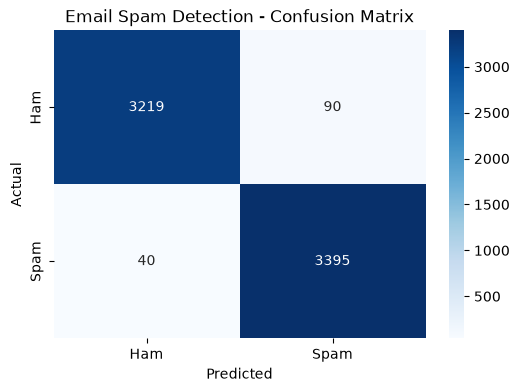

In [51]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Ham', 'Spam'],
    yticklabels=['Ham', 'Spam']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Email Spam Detection - Confusion Matrix')
plt.show()

In [52]:
def predict_email(email):

    cleaned_email = email.lower()

    cleaned_email = re.sub(
        r'[^a-zA-Z0-9\s]',
        ' ',
        cleaned_email
    )

    cleaned_email = re.sub(
        r'\s+',
        ' ',
        cleaned_email
    ).strip()

    email_tfidf = tfidf.transform([cleaned_email])

    prediction = model.predict(email_tfidf)

    if prediction[0] == 1:
        return "Spam Email"

    else:
        return "Ham (Normal) Email"

In [53]:
email1 = "Hello, please attend the project meeting tomorrow at 10 AM."

print(predict_email(email1))

Ham (Normal) Email


In [54]:
email2 = "Congratulations! You have won a free lottery prize. Claim your cash now!"

print(predict_email(email2))

Spam Email


In [55]:
email3 = "Dear student, your examination results have been published. Please check the university website."

print(predict_email(email3))

Spam Email


In [56]:
email3 = "Dear student, your examination results have been published. Please check the university website."

cleaned_email = email3.lower()
cleaned_email = re.sub(r'[^a-zA-Z0-9\s]', ' ', cleaned_email)
cleaned_email = re.sub(r'\s+', ' ', cleaned_email).strip()

email_vector = tfidf.transform([cleaned_email])

probabilities = model.predict_proba(email_vector)

print("Ham Probability:", probabilities[0][0] * 100, "%")
print("Spam Probability:", probabilities[0][1] * 100, "%")

Ham Probability: 45.18067969474897 %
Spam Probability: 54.819320305251104 %


In [57]:
email4 = "Hi John, attached are the notes from our meeting. Please review them before Friday."

print(predict_email(email4))

Ham (Normal) Email


In [58]:
import os
import joblib

# Create models folder
os.makedirs("../models", exist_ok=True)

# Save trained model
joblib.dump(model, "../models/spam_model.pkl")

# Save TF-IDF vectorizer
joblib.dump(tfidf, "../models/tfidf_vectorizer.pkl")

print("Model and vectorizer saved successfully!")

Model and vectorizer saved successfully!
